# Ensemble Learning with Scikit-Learn, CatBoost, and XGBoost

This notebook provides complete, hands-on implementations and evaluations of the seven primary **Ensemble Learning** paradigms using built-in **scikit-learn** datasets:

1. **Bagging (Bootstrap Aggregating)** — *Variance reduction via bootstrap replicas & Out-of-Bag (OOB) scoring*
2. **Boosting (AdaBoost)** — *Sequential bias reduction via adaptive sample re-weighting*
3. **Stacking (Stacked Generalization)** — *Heterogeneous multi-model ensemble with meta-learner*
4. **Random Forest** — *De-correlated tree ensemble via Random Subspace feature sampling*
5. **Gradient Boosting (GBDT)** — *Sequential optimization of pseudo-residuals and loss functions*
6. **CatBoost (Categorical Boosting)** — *Symmetric/oblivious trees & ordered boosting*
7. **XGBoost (Extreme Gradient Boosting)** — *Second-order Taylor loss optimization & regularized tree pruning*
8. **Comprehensive Ensemble Benchmark & Model Comparison** — *Cross-model performance leaderboard*
9. **Comparative Architecture Summary Guide**

---

### Pedagogical Template (8-Step Architecture):
To maximize educational clarity for students and serve as a structured revision guide, every ensemble algorithm section is organized into the uniform 8-step workflow:
1. **Importing** — Libraries, model estimators, and metric functions.
2. **Loading Dataset** — Dataset loading, shape inspection, feature/target exploration.
3. **Split** — Train-test split, stratified sampling, and feature scaling where needed.
4. **Train** — Model initialization and hyperparameter configuration.
5. **Fit** — Fitting the estimator on training data (`.fit()`).
6. **Predict** — Generating test predictions (`.predict()`).
7. **Evaluation** — Performance metrics (`accuracy_score`, `classification_report`, `confusion_matrix`, and OOB score).
8. **Visualization** — Diagnostic plots (Confusion matrix displays, learning curves, feature importance bar charts, OOB error curves).


---
# 1. Bagging (Bootstrap Aggregating)

Bagging is a parallel ensemble technique aimed at **reducing the variance** of high-variance, low-bias base estimators (such as unpruned Decision Trees).

**How Bagging Works:**
1. **Bootstrap Sampling:** Given a training dataset $\mathcal{D}$ of size $N$, draw $B$ independent datasets $\mathcal{D}_1, \dots, \mathcal{D}_B$ of size $N$ with replacement.
   - On average, each bootstrap sample contains approximately $1 - \frac{1}{e} \approx 63.2\%$ of unique samples from $\mathcal{D}$.
   - The remaining $\approx 36.8\%$ of unseen instances form the **Out-of-Bag (OOB)** sample.
2. **Independent Training:** Train an independent base estimator $h_b(x)$ on each bootstrap sample $\mathcal{D}_b$.
3. **Aggregation:**
   - **Classification:** Majority voting $\hat{y} = \text{mode}\{h_1(x), \dots, h_B(x)\}$.
   - **Regression:** Averaging $\hat{y} = \frac{1}{B} \sum_{b=1}^B h_b(x)$.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> **"The Wisdom of the Crowd."** If you ask one person at a county fair to guess how many jellybeans are in a giant glass jar, their guess might be way too high or way too low. But if you ask 100 different people and calculate the average of all their guesses, the crazy high guesses cancel out the crazy low guesses, and the average is astonishingly close to the true count! That is Bagging.


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
**Key Functions Explained:**
- `BaggingClassifier`: Ensemble meta-estimator that fits base classifiers on random subsets of the dataset.
- `DecisionTreeClassifier`: Base learner used inside the bagging ensemble.
- `accuracy_score`, `classification_report`, `confusion_matrix`: Evaluation metrics.


In [1]:
# 1. Importing libraries for Bagging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Loading Breast Cancer Wisconsin dataset (569 samples, 30 features, Malignant=0, Benign=1).

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [2]:
# 2. Loading Dataset
cancer_bag = load_breast_cancer(as_frame=True)
df_cancer_bag = cancer_bag.frame

X_bag = df_cancer_bag[cancer_bag.feature_names]
y_bag = df_cancer_bag['target']

print(f"Dataset Shape: {X_bag.shape} (569 samples, 30 features)")
print("Classes:", cancer_bag.target_names)
display(df_cancer_bag.head(3))


Dataset Shape: (569, 30) (569 samples, 30 features)
Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Partitioning data into 75% train and 25% test with stratified sampling (`stratify=y_bag`).


In [3]:
# 3. Train/Test Split
X_train_bag, X_test_bag, y_train_bag, y_test_bag = train_test_split(
    X_bag, y_bag, test_size=0.25, random_state=42, stratify=y_bag
)

print(f"Training samples: {len(X_train_bag)} | Testing samples: {len(X_test_bag)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters Explained:**
- `estimator=DecisionTreeClassifier(random_state=42)`: Base learner to clone and train on bootstrap subsets.
- `n_estimators=100`: Number of bootstrap trees to build.
- `oob_score=True`: Evaluates generalized error on out-of-bag samples without needing a separate validation split.
- `n_jobs=-1`: Utilizes all available CPU cores in parallel.


In [4]:
# 4. Train: Model Initialization
single_tree = DecisionTreeClassifier(random_state=42)

bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

print("Baseline Single Tree and Bagging Ensemble initialized.")


Baseline Single Tree and Bagging Ensemble initialized.


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting both the single decision tree baseline and the 100-tree Bagging ensemble.


In [5]:
# 5. Fit: Model Training
single_tree.fit(X_train_bag, y_train_bag)
bag_clf.fit(X_train_bag, y_train_bag)

print(f"Bagging ensemble fitted! OOB Score: {bag_clf.oob_score_:.4f}")


Bagging ensemble fitted! OOB Score: 0.9554


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating test predictions from both models.


In [6]:
# 6. Predict: Model Inference
y_pred_single = single_tree.predict(X_test_bag)
y_pred_bag = bag_clf.predict(X_test_bag)

print("First 10 Bagging Predictions:", y_pred_bag[:10])


First 10 Bagging Predictions: [1 0 0 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating Single Tree vs. Bagging Ensemble: accuracy gain, OOB score, classification report, and confusion matrix.


In [7]:
# 7. Evaluation
acc_single = accuracy_score(y_test_bag, y_pred_single)
acc_bag = accuracy_score(y_test_bag, y_pred_bag)
cm_bag = confusion_matrix(y_test_bag, y_pred_bag)

print("=" * 60)
print("BAGGING ENSEMBLE EVALUATION REPORT")
print("=" * 60)
print(f"Single Decision Tree Accuracy:   {acc_single:.4f} ({acc_single*100:.2f}%)")
print(f"Bagging Ensemble (100 Trees):    {acc_bag:.4f} ({acc_bag*100:.2f}%)")
print(f"Out-of-Bag (OOB) Accuracy Score: {bag_clf.oob_score_:.4f} ({bag_clf.oob_score_*100:.2f}%)")
print(f"Variance Reduction Gain:         +{(acc_bag - acc_single)*100:.2f}%")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_bag, y_pred_bag, target_names=cancer_bag.target_names))


BAGGING ENSEMBLE EVALUATION REPORT
Single Decision Tree Accuracy:   0.9231 (92.31%)
Bagging Ensemble (100 Trees):    0.9510 (95.10%)
Out-of-Bag (OOB) Accuracy Score: 0.9554 (95.54%)
Variance Reduction Gain:         +2.80%
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.94      0.92      0.93        53
      benign       0.96      0.97      0.96        90

    accuracy                           0.95       143
   macro avg       0.95      0.95      0.95       143
weighted avg       0.95      0.95      0.95       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
**Visualizations:**
1. **Single Tree vs. Bagging Accuracy Bar Chart:** Visualizes accuracy gain.
2. **Confusion Matrix Heatmap:** Breakdown of true vs. false predictions.
3. **OOB Score Convergence Curve:** Variance reduction as number of trees grows from 20 to 150.


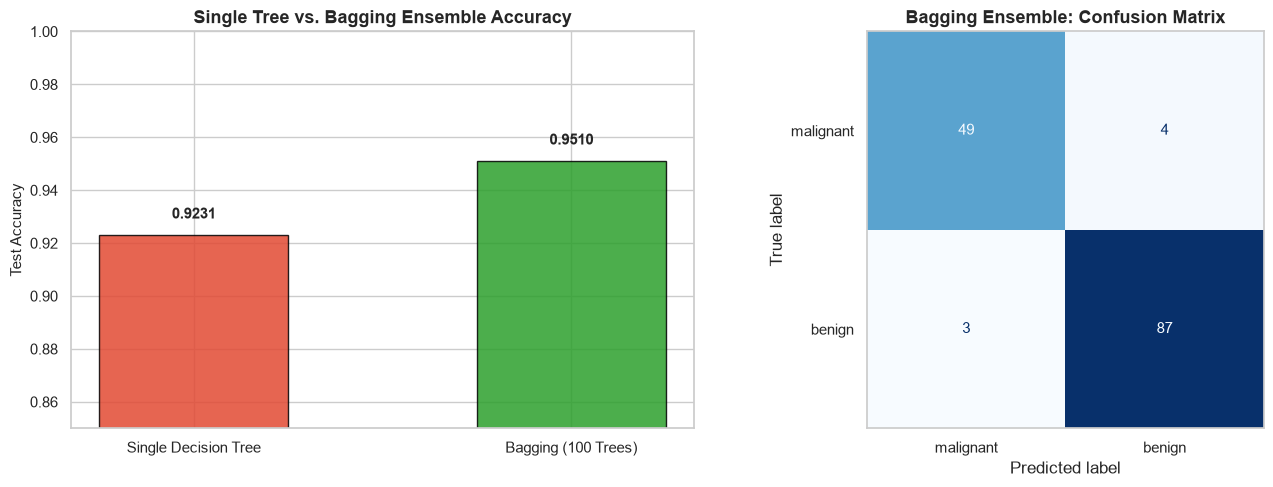

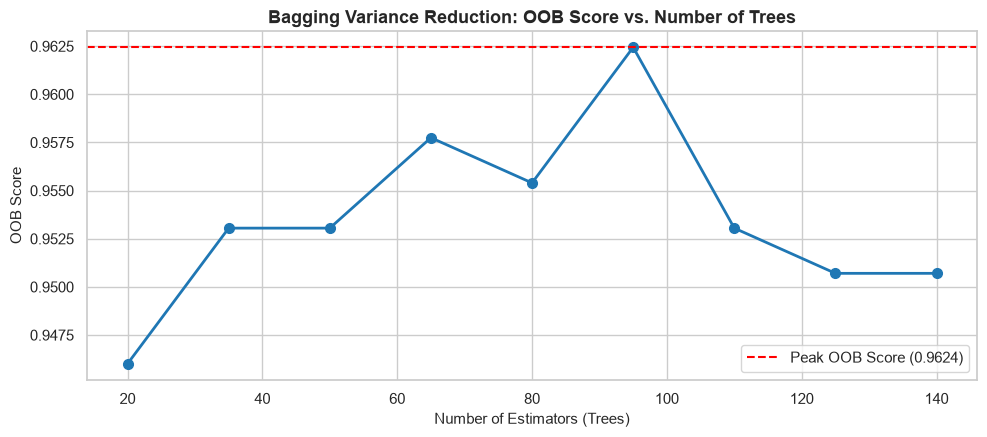

In [8]:
# 8. Visualization: Accuracy Comparison, Confusion Matrix & OOB Convergence
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Accuracy Comparison
bars = axes[0].bar(
    ["Single Decision Tree", "Bagging (100 Trees)"],
    [acc_single, acc_bag],
    color=["#e24a33", "#2ca02c"],
    edgecolor="black",
    alpha=0.85,
    width=0.5
)
axes[0].set_ylim(0.85, 1.0)
axes[0].set_title("Single Tree vs. Bagging Ensemble Accuracy", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Test Accuracy", fontsize=11)
for b in bars:
    axes[0].text(b.get_x() + b.get_width()/2.0, b.get_height() + 0.005, f"{b.get_height():.4f}", ha='center', va='bottom', fontweight='bold')

# Plot 2: Confusion Matrix
disp_bag = ConfusionMatrixDisplay(confusion_matrix=cm_bag, display_labels=cancer_bag.target_names)
disp_bag.plot(cmap="Blues", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Bagging Ensemble: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()

# Plot 3: OOB Score vs. Number of Estimators
n_trees_range = range(20, 151, 15)
oob_scores = []
for n in n_trees_range:
    clf = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=n, oob_score=True, random_state=42, n_jobs=-1)
    clf.fit(X_train_bag, y_train_bag)
    oob_scores.append(clf.oob_score_)

plt.figure(figsize=(10, 4.5))
plt.plot(n_trees_range, oob_scores, marker='o', color='#1f77b4', linewidth=2, markersize=7)
plt.axhline(y=max(oob_scores), color='red', linestyle='--', label=f'Peak OOB Score ({max(oob_scores):.4f})')
plt.title("Bagging Variance Reduction: OOB Score vs. Number of Trees", fontsize=13, fontweight="bold")
plt.xlabel("Number of Estimators (Trees)", fontsize=11)
plt.ylabel("OOB Score", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


---
# 2. Boosting (AdaBoost)

AdaBoost (Adaptive Boosting) is a sequential ensemble method that converts a collection of **weak learners** (decision stumps with `max_depth=1`) into a **strong learner** by focusing on **bias reduction**:
$$\hat{y}(x) = \text{sign}\left(\sum_{m=1}^M \alpha_m h_m(x)\right)$$

At each round, misclassified samples have their weights increased:
$$w_i \leftarrow w_i \exp\left(-\alpha_m y_i h_m(x_i)\right), \quad \text{where } \alpha_m = \frac{1}{2}\ln\left(\frac{1 - \epsilon_m}{\epsilon_m}\right)$$

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine a student studying math flashcards with a dedicated tutor:
> - On Test 1, the student gets flashcards #4 and #9 wrong.
> - For Test 2, the tutor puts giant bright red stars on #4 and #9 and makes the student spend 80% of their study time on them.
> Step-by-step, every new test focuses on the specific mistakes made previously until the student masters the entire subject!


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for AdaBoost.


In [9]:
# 1. Importing libraries for AdaBoost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [10]:
# 2. Loading Dataset
cancer_ada = load_breast_cancer(as_frame=True)
X_ada = cancer_ada.data
y_ada = cancer_ada.target
display(X_ada.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25 with stratified sampling).


In [11]:
# 3. Train/Test Split
X_train_ada, X_test_ada, y_train_ada, y_test_ada = train_test_split(
    X_ada, y_ada, test_size=0.25, random_state=42, stratify=y_ada
)
print(f"Training samples: {len(X_train_ada)} | Testing samples: {len(X_test_ada)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters:**
- `estimator=DecisionTreeClassifier(max_depth=1)`: Decision stump (weak learner).
- `n_estimators=100`: Maximum number of sequential boosting stages.
- `learning_rate=0.5`: Shrinks contribution of each weak learner to prevent overfitting.


In [12]:
# 4. Train: Model Initialization
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
adaboost = AdaBoostClassifier(
    estimator=stump,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
print("AdaBoost model initialized:", adaboost)


AdaBoost model initialized: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=42),
                   learning_rate=0.5, n_estimators=100, random_state=42)


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Sequential stage-wise fitting with adaptive sample re-weighting.


In [13]:
# 5. Fit: Model Training
adaboost.fit(X_train_ada, y_train_ada)
print("AdaBoost training complete across 100 boosting stages!")


AdaBoost training complete across 100 boosting stages!


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions on test set.


In [14]:
# 6. Predict: Model Inference
y_pred_ada = adaboost.predict(X_test_ada)
print("First 10 AdaBoost Predictions:", y_pred_ada[:10])


First 10 AdaBoost Predictions: [1 0 1 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating AdaBoost performance metrics.


In [15]:
# 7. Evaluation
acc_ada = accuracy_score(y_test_ada, y_pred_ada)
cm_ada = confusion_matrix(y_test_ada, y_pred_ada)

print("=" * 60)
print(f"ADABOOST ACCURACY SCORE: {acc_ada:.4f} ({acc_ada*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_ada, y_pred_ada, target_names=cancer_ada.target_names))


ADABOOST ACCURACY SCORE: 0.9650 (96.50%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.98      0.92      0.95        53
      benign       0.96      0.99      0.97        90

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
Visualizing the staged accuracy progression across all 100 boosting rounds and the Confusion Matrix.


d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
d:\Github\ACC-HPC2026-AIML\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


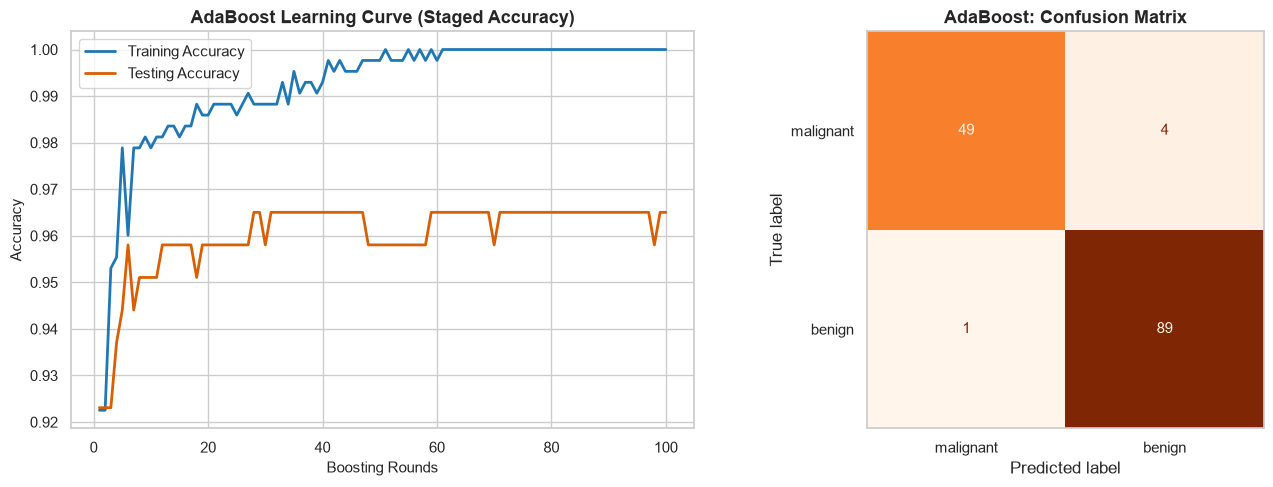

In [16]:
# 8. Visualization: Staged Accuracy Progression & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Staged Score Progression
staged_train = list(adaboost.staged_score(X_train_ada, y_train_ada))
staged_test = list(adaboost.staged_score(X_test_ada, y_test_ada))

axes[0].plot(range(1, 101), staged_train, label="Training Accuracy", color="#1f77b4", linewidth=2)
axes[0].plot(range(1, 101), staged_test, label="Testing Accuracy", color="#d95f02", linewidth=2)
axes[0].set_title("AdaBoost Learning Curve (Staged Accuracy)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Boosting Rounds", fontsize=11)
axes[0].set_ylabel("Accuracy", fontsize=11)
axes[0].legend()

# Plot 2: Confusion Matrix
disp_ada = ConfusionMatrixDisplay(confusion_matrix=cm_ada, display_labels=cancer_ada.target_names)
disp_ada.plot(cmap="Oranges", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("AdaBoost: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()


---
# 3. Stacking (Stacked Generalization)

Stacking combines multiple **heterogeneous model families** (e.g., Random Forest, Scaled KNN, Gaussian Naive Bayes) using an out-of-fold cross-validated **meta-learner** (`LogisticRegression`).
- **Level-0:** Base models generate predictions via 5-fold cross-validation.
- **Level-1:** Meta-model learns how to optimally blend the base models' predictions.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Consulting a panel of diverse specialists:
> - Doctor 1 is a Radiologist (Random Forest).
> - Doctor 2 is a Cardiologist (KNN).
> - Doctor 3 is a General Physician (Naïve Bayes).
> Instead of a naive vote, you hire a **Chief Medical Officer (the Meta-Learner)** who reviews all three doctors' opinions. The Chief knows which doctor is most reliable for specific symptoms and combines their findings to make the final diagnosis!


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for Stacking Classifier and diverse base learners.


In [17]:
# 1. Importing libraries for Stacking
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [18]:
# 2. Loading Dataset
cancer_stack = load_breast_cancer(as_frame=True)
X_stack = cancer_stack.data
y_stack = cancer_stack.target
display(X_stack.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25).


In [19]:
# 3. Train/Test Split
X_train_stack, X_test_stack, y_train_stack, y_test_stack = train_test_split(
    X_stack, y_stack, test_size=0.25, random_state=42, stratify=y_stack
)
print(f"Training samples: {len(X_train_stack)} | Testing samples: {len(X_test_stack)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization & Architecture)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Architecture:**
- Level-0 Estimators:
  1. `RandomForestClassifier(n_estimators=50)` (Tree-based)
  2. `Pipeline(StandardScaler, KNeighborsClassifier)` (Distance-based instance learner)
  3. `GaussianNB` (Probabilistic model)
- Level-1 Meta-Learner: `LogisticRegression`
- `cv=5`: 5-fold out-of-fold cross validation.


In [20]:
# 4. Train: Model Initialization
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=50, random_state=42)),
    ('knn', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
    ('nb', GaussianNB())
]

final_meta_learner = LogisticRegression(random_state=42)

stack_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=final_meta_learner,
    cv=5,
    n_jobs=-1
)
print("Stacking Classifier initialized with 3 heterogeneous base estimators.")


Stacking Classifier initialized with 3 heterogeneous base estimators.


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting Level-0 models and Level-1 meta-learner.


In [21]:
# 5. Fit: Model Training
stack_clf.fit(X_train_stack, y_train_stack)

# Also fit base models individually on test set to compare performance
base_scores = {}
for name, estimator in base_estimators:
    estimator.fit(X_train_stack, y_train_stack)
    base_scores[name] = accuracy_score(y_test_stack, estimator.predict(X_test_stack))

print("Stacking ensemble trained successfully!")


Stacking ensemble trained successfully!


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions from the stacked meta-model.


In [22]:
# 6. Predict: Model Inference
y_pred_stack = stack_clf.predict(X_test_stack)
print("First 10 Stacking Predictions:", y_pred_stack[:10])


First 10 Stacking Predictions: [1 0 1 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Comparing individual base model accuracies against the Stacking ensemble.


In [23]:
# 7. Evaluation
acc_stack = accuracy_score(y_test_stack, y_pred_stack)
cm_stack = confusion_matrix(y_test_stack, y_pred_stack)

print("=" * 60)
print("STACKING CLASSIFIER EVALUATION REPORT")
print("=" * 60)
print(f"Base Model 1 (Random Forest) Accuracy: {base_scores['rf']:.4f}")
print(f"Base Model 2 (Scaled KNN) Accuracy:    {base_scores['knn']:.4f}")
print(f"Base Model 3 (Gaussian NB) Accuracy:   {base_scores['nb']:.4f}")
print(f"Stacking Meta-Model Accuracy:          {acc_stack:.4f} ({acc_stack*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_stack, y_pred_stack, target_names=cancer_stack.target_names))


STACKING CLASSIFIER EVALUATION REPORT
Base Model 1 (Random Forest) Accuracy: 0.9510
Base Model 2 (Scaled KNN) Accuracy:    0.9790
Base Model 3 (Gaussian NB) Accuracy:   0.9371
Stacking Meta-Model Accuracy:          0.9510 (95.10%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.96      0.91      0.93        53
      benign       0.95      0.98      0.96        90

    accuracy                           0.95       143
   macro avg       0.95      0.94      0.95       143
weighted avg       0.95      0.95      0.95       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
Bar chart comparing base models vs. Stacking Meta-Learner and Confusion Matrix heatmap.


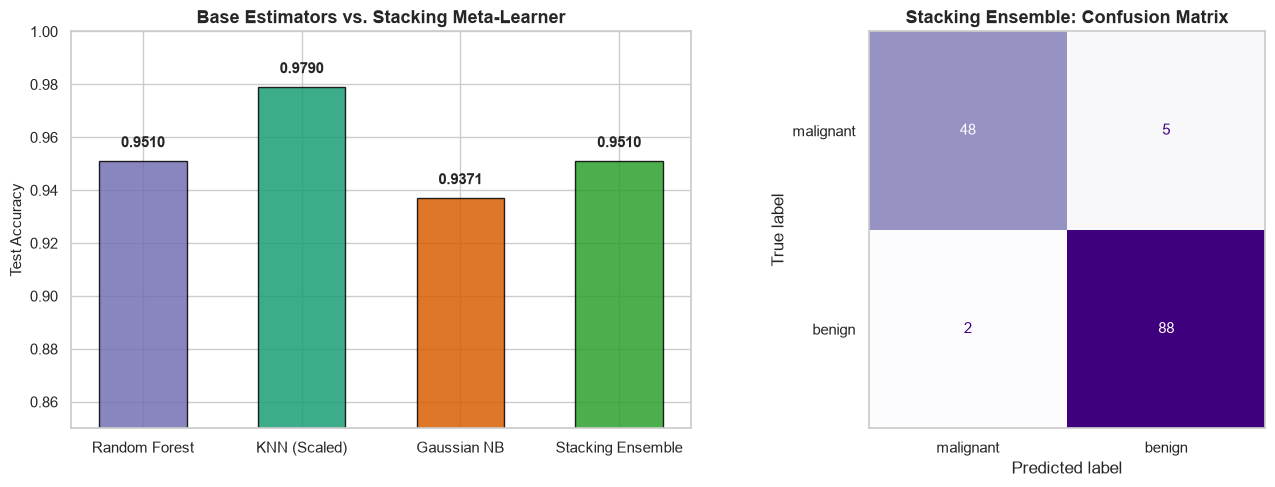

In [24]:
# 8. Visualization: Base Models vs Meta-Model & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Model Comparison Bar Chart
model_names = ['Random Forest', 'KNN (Scaled)', 'Gaussian NB', 'Stacking Ensemble']
accuracies = [base_scores['rf'], base_scores['knn'], base_scores['nb'], acc_stack]
colors = ['#7570b3', '#1b9e77', '#d95f02', '#2ca02c']

bars = axes[0].bar(model_names, accuracies, color=colors, edgecolor='black', alpha=0.85, width=0.55)
axes[0].set_ylim(0.85, 1.0)
axes[0].set_title("Base Estimators vs. Stacking Meta-Learner", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Test Accuracy", fontsize=11)
for b in bars:
    axes[0].text(b.get_x() + b.get_width()/2.0, b.get_height() + 0.004, f"{b.get_height():.4f}", ha='center', va='bottom', fontweight='bold')

# Plot 2: Confusion Matrix
disp_stack = ConfusionMatrixDisplay(confusion_matrix=cm_stack, display_labels=cancer_stack.target_names)
disp_stack.plot(cmap="Purples", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Stacking Ensemble: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()


---
# 4. Random Forest

Random Forest extends Bagging by introducing **feature randomness (Random Subspace Method)**:
- At each split, only a random subset of $m = \sqrt{p}$ features is evaluated.
- This de-correlates the individual trees, preventing dominant features from dictating every top split and yielding lower ensemble variance.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine a murder mystery game with 100 detectives. If all 100 detectives look at the bloody fingerprint first, they might all get tricked by a fake clue!
> In a **Random Forest**, you blindfold the detectives so each one only gets to look at 3 random clues (e.g., Detective A only sees shoes and alibis; Detective B only sees phone logs and bank statements). Because they look at completely different evidence, the forest as a whole cannot be fooled by misleading clues!


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for Random Forest.


In [25]:
# 1. Importing libraries for Random Forest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [26]:
# 2. Loading Dataset
cancer_rf = load_breast_cancer(as_frame=True)
X_rf = cancer_rf.data
y_rf = cancer_rf.target
display(X_rf.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25).


In [27]:
# 3. Train/Test Split
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.25, random_state=42, stratify=y_rf
)
print(f"Training samples: {len(X_train_rf)} | Testing samples: {len(X_test_rf)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters:**
- `n_estimators=100`: Number of trees in the forest.
- `max_features='sqrt'`: Evaluates only $\sqrt{30} \approx 5$ random features at each split to de-correlate trees.
- `oob_score=True`: Computes Out-of-Bag generalization score.


In [28]:
# 4. Train: Model Initialization
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
print("Random Forest model initialized:", rf_clf)


Random Forest model initialized: RandomForestClassifier(n_jobs=-1, oob_score=True, random_state=42)


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting 100 de-correlated trees in parallel.


In [29]:
# 5. Fit: Model Training
rf_clf.fit(X_train_rf, y_train_rf)
print(f"Random Forest fitted! Out-of-Bag (OOB) Score: {rf_clf.oob_score_:.4f}")


Random Forest fitted! Out-of-Bag (OOB) Score: 0.9624


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions on test set.


In [30]:
# 6. Predict: Model Inference
y_pred_rf = rf_clf.predict(X_test_rf)
print("First 10 Random Forest Predictions:", y_pred_rf[:10])


First 10 Random Forest Predictions: [1 0 1 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating Accuracy, OOB Score, Classification Report, and Confusion Matrix.


In [31]:
# 7. Evaluation
acc_rf = accuracy_score(y_test_rf, y_pred_rf)
cm_rf = confusion_matrix(y_test_rf, y_pred_rf)

print("=" * 60)
print("RANDOM FOREST EVALUATION REPORT")
print("=" * 60)
print(f"Overall Test Accuracy:  {acc_rf:.4f} ({acc_rf*100:.2f}%)")
print(f"Out-of-Bag (OOB) Score: {rf_clf.oob_score_:.4f} ({rf_clf.oob_score_*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_rf, y_pred_rf, target_names=cancer_rf.target_names))


RANDOM FOREST EVALUATION REPORT
Overall Test Accuracy:  0.9580 (95.80%)
Out-of-Bag (OOB) Score: 0.9624 (96.24%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
**Visualizations:**
1. **Top 15 Feature Importances (MDI):** Relative importance of features based on total Gini impurity decrease.
2. **Confusion Matrix Heatmap.**
3. **OOB Error vs. Tree Count:** Visualizing error stabilization as forest size grows ($N \in [20, 200]$).


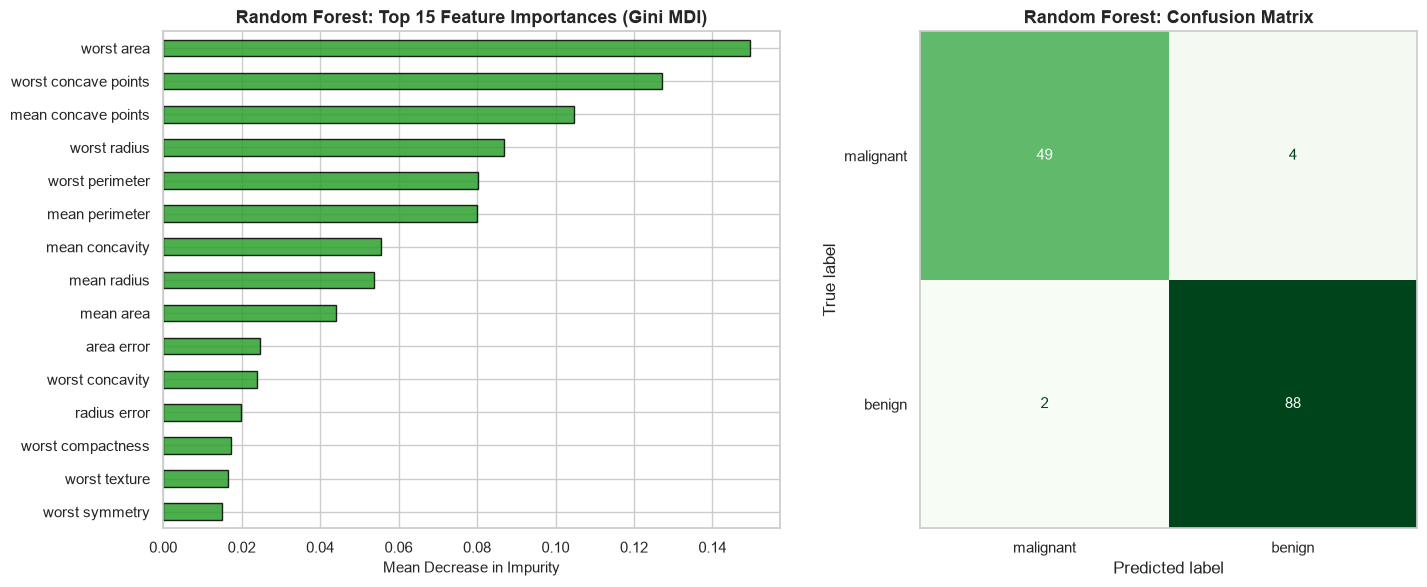

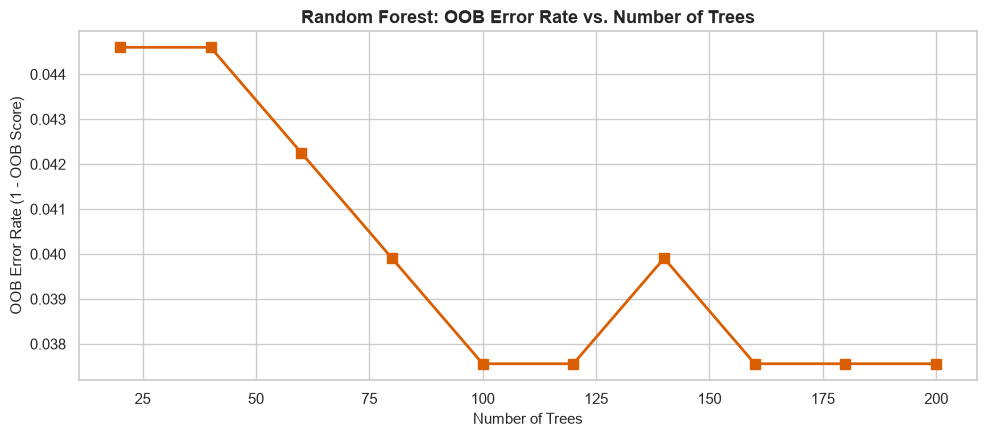

In [32]:
# 8. Visualization: Feature Importances, Confusion Matrix & OOB Error Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Feature Importances
rf_importances = pd.Series(rf_clf.feature_importances_, index=cancer_rf.feature_names).sort_values(ascending=False).head(15)
rf_importances.sort_values().plot(kind="barh", ax=axes[0], color="#2ca02c", edgecolor="black", alpha=0.85)
axes[0].set_title("Random Forest: Top 15 Feature Importances (Gini MDI)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Mean Decrease in Impurity", fontsize=11)

# Plot 2: Confusion Matrix
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=cancer_rf.target_names)
disp_rf.plot(cmap="Greens", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Random Forest: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()

# Plot 3: OOB Error vs. Number of Trees
tree_counts = range(20, 201, 20)
oob_errors = []
for n in tree_counts:
    rf_temp = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train_rf, y_train_rf)
    oob_errors.append(1.0 - rf_temp.oob_score_)

plt.figure(figsize=(10, 4.5))
plt.plot(tree_counts, oob_errors, marker='s', color='#d95f02', linewidth=2, markersize=7)
plt.title("Random Forest: OOB Error Rate vs. Number of Trees", fontsize=13, fontweight="bold")
plt.xlabel("Number of Trees", fontsize=11)
plt.ylabel("OOB Error Rate (1 - OOB Score)", fontsize=11)
plt.tight_layout()
plt.show()


---
# 5. Gradient Boosting (GBDT)

Gradient Boosted Decision Trees (GBDT) builds an additive model by sequentially fitting trees to the **pseudo-residuals** (negative gradients of the loss function):
$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x), \quad \text{where } r_{im} = -\left[\frac{\partial L(y_i, F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}}$$

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine playing miniature golf:
> - Your first putt lands 4 feet short of the hole (that 4-foot distance is your **residual / error**).
> - Your second stroke does not start over from the tee; it aims specifically to fix that 4-foot gap!
> - Your third stroke fixes the remaining 2-inch error until the ball drops into the cup.
> Each new tree specifically targets and corrects the remaining errors of all previous trees.


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for Gradient Boosting and log loss.


In [33]:
# 1. Importing libraries for Gradient Boosting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [34]:
# 2. Loading Dataset
cancer_gb = load_breast_cancer(as_frame=True)
X_gb = cancer_gb.data
y_gb = cancer_gb.target
display(X_gb.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25).


In [35]:
# 3. Train/Test Split
X_train_gb, X_test_gb, y_train_gb, y_test_gb = train_test_split(
    X_gb, y_gb, test_size=0.25, random_state=42, stratify=y_gb
)
print(f"Training samples: {len(X_train_gb)} | Testing samples: {len(X_test_gb)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters:**
- `learning_rate=0.1`: Step size shrinkage $\eta$.
- `n_estimators=100`: Number of boosting iterations.
- `max_depth=3`: Depth of individual regression trees.
- `subsample=0.8`: Stochastic gradient boosting (samples 80% of rows per tree).


In [36]:
# 4. Train: Model Initialization
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    random_state=42
)
print("Gradient Boosting model initialized:", gb_clf)


Gradient Boosting model initialized: GradientBoostingClassifier(random_state=42, subsample=0.8)


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting gradient boosting model on training residuals.


In [37]:
# 5. Fit: Model Training
gb_clf.fit(X_train_gb, y_train_gb)
print("Gradient Boosting training complete!")


Gradient Boosting training complete!


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions on test set.


In [38]:
# 6. Predict: Model Inference
y_pred_gb = gb_clf.predict(X_test_gb)
print("First 10 GBDT Predictions:", y_pred_gb[:10])


First 10 GBDT Predictions: [1 0 1 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating GBDT metrics.


In [39]:
# 7. Evaluation
acc_gb = accuracy_score(y_test_gb, y_pred_gb)
cm_gb = confusion_matrix(y_test_gb, y_pred_gb)

print("=" * 60)
print(f"GRADIENT BOOSTING ACCURACY: {acc_gb:.4f} ({acc_gb*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_gb, y_pred_gb, target_names=cancer_gb.target_names))


GRADIENT BOOSTING ACCURACY: 0.9580 (95.80%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.98      0.91      0.94        53
      benign       0.95      0.99      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
Deviance (log-loss) progression curves for training vs. test sets across 100 boosting stages and Confusion Matrix.


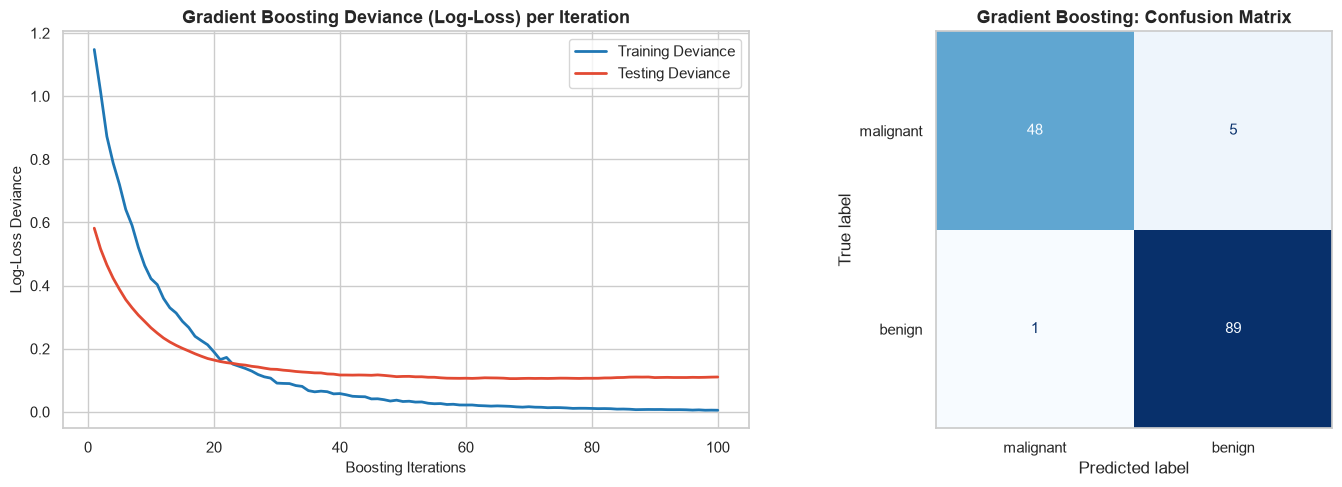

In [40]:
# 8. Visualization: Deviance Curves & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Deviance Curve
test_deviance = [log_loss(y_test_gb, prob) for prob in gb_clf.staged_predict_proba(X_test_gb)]
train_deviance = gb_clf.train_score_

axes[0].plot(range(1, 101), train_deviance, label="Training Deviance", color="#1f77b4", linewidth=2)
axes[0].plot(range(1, 101), test_deviance, label="Testing Deviance", color="#e24a33", linewidth=2)
axes[0].set_title("Gradient Boosting Deviance (Log-Loss) per Iteration", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Boosting Iterations", fontsize=11)
axes[0].set_ylabel("Log-Loss Deviance", fontsize=11)
axes[0].legend()

# Plot 2: Confusion Matrix
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=cancer_gb.target_names)
disp_gb.plot(cmap="Blues", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Gradient Boosting: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()


---
# 6. CatBoost (Categorical Boosting)

CatBoost (Yandex) is an advanced gradient boosting framework designed for high prediction accuracy and speed:
- **Symmetric / Oblivious Trees:** The same split is used across all leaves at the same depth level, acting as strong regularization against overfitting and speeding up inference.
- **Ordered Boosting:** Overcomes prediction shift / target leakage through random dataset permutations.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> A super-smart robot engine that loves words and categories! Most algorithms panic when they see words like "Toyota", "Ford", or "Blue" and demand that you convert them into numbers first. CatBoost understands categories naturally and builds perfectly balanced, mirror-image decisions (**symmetric oblivious trees**) that make it blazing fast!


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for CatBoost.


In [41]:
# 1. Importing libraries for CatBoost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [42]:
# 2. Loading Dataset
cancer_cb = load_breast_cancer(as_frame=True)
X_cb = cancer_cb.data
y_cb = cancer_cb.target
display(X_cb.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25).


In [43]:
# 3. Train/Test Split
X_train_cb, X_test_cb, y_train_cb, y_test_cb = train_test_split(
    X_cb, y_cb, test_size=0.25, random_state=42, stratify=y_cb
)
print(f"Training samples: {len(X_train_cb)} | Testing samples: {len(X_test_cb)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters:**
- `iterations=100`: Number of boosting trees.
- `learning_rate=0.1`: Shrinkage rate.
- `depth=4`: Tree depth (oblivious trees).
- `verbose=0`: Silent training.


In [44]:
# 4. Train: Model Initialization
cat_clf = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=4,
    eval_metric='Logloss',
    verbose=0,
    random_state=42
)
print("CatBoost model initialized:", cat_clf)


CatBoost model initialized: CatBoostClassifier(depth=4, eval_metric='Logloss', iterations=100, learning_rate=0.1, random_state=42, verbose=0)


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting CatBoost on training data with test validation monitoring.


In [45]:
# 5. Fit: Model Training
cat_clf.fit(X_train_cb, y_train_cb, eval_set=(X_test_cb, y_test_cb), verbose=False)
print("CatBoost model training complete!")


CatBoost model training complete!


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions on test set.


In [46]:
# 6. Predict: Model Inference
y_pred_cb = cat_clf.predict(X_test_cb)
print("First 10 CatBoost Predictions:", y_pred_cb[:10])


First 10 CatBoost Predictions: [1 0 1 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating CatBoost metrics.


In [47]:
# 7. Evaluation
acc_cb = accuracy_score(y_test_cb, y_pred_cb)
cm_cb = confusion_matrix(y_test_cb, y_pred_cb)

print("=" * 60)
print(f"CATBOOST ACCURACY SCORE: {acc_cb:.4f} ({acc_cb*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_cb, y_pred_cb, target_names=cancer_cb.target_names))


CATBOOST ACCURACY SCORE: 0.9650 (96.50%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       1.00      0.91      0.95        53
      benign       0.95      1.00      0.97        90

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
Visualizing Top 15 Feature Importances and Confusion Matrix.


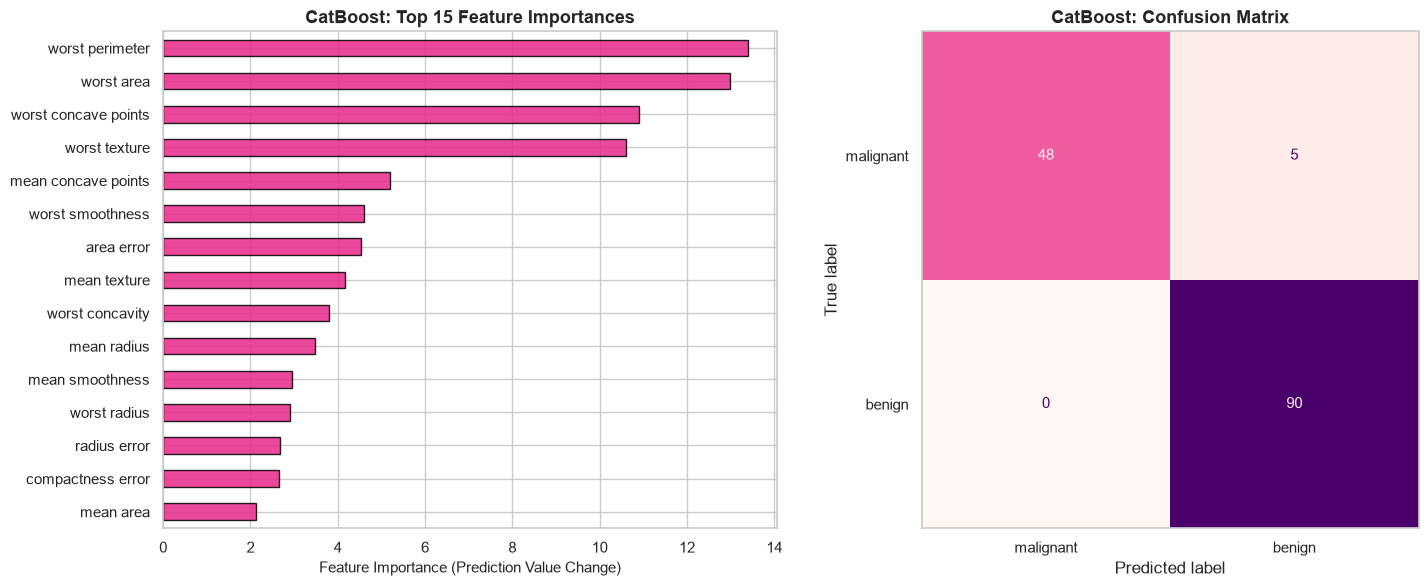

In [48]:
# 8. Visualization: Feature Importances & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Feature Importances
cb_importances = pd.Series(cat_clf.get_feature_importance(), index=cancer_cb.feature_names).sort_values(ascending=False).head(15)
cb_importances.sort_values().plot(kind="barh", ax=axes[0], color="#e7298a", edgecolor="black", alpha=0.85)
axes[0].set_title("CatBoost: Top 15 Feature Importances", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Feature Importance (Prediction Value Change)", fontsize=11)

# Plot 2: Confusion Matrix
disp_cb = ConfusionMatrixDisplay(confusion_matrix=cm_cb, display_labels=cancer_cb.target_names)
disp_cb.plot(cmap="RdPu", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("CatBoost: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()


---
# 7. XGBoost (Extreme Gradient Boosting)

XGBoost is an industry-leading gradient boosting framework featuring:
- **Second-Order Taylor Approximation:** Optimizes loss using both first-order gradients $g_i$ and second-order Hessians $h_i$.
- **Explicit Regularization:** Direct leaf complexity penalty $\Omega(f) = \gamma T + \frac{1}{2}\lambda \sum w_j^2$ preventing overfitting.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> The **Formula 1 racing car** of machine learning! It uses gradient boosting but is engineered with turbochargers (parallel CPU processing) and smart disc brakes (**regularization**). The brakes prevent the car from memorizing the racetrack too closely (overfitting), allowing it to win machine learning competitions around the world!


### Step 1: Importing

> 💡 *Beginner Tip:* We import our ensemble classes, base decision trees, and classification report metrics.
Imports for XGBoost.


In [49]:
# 1. Importing libraries for XGBoost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



### Step 2: Loading Dataset

> 💡 *Beginner Tip:* We load our feature table and verify target balance (e.g., malignant vs. benign samples).
Using Breast Cancer Wisconsin dataset.

[`Breast Cancer Dataset`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)


In [50]:
# 2. Loading Dataset
cancer_xgb = load_breast_cancer(as_frame=True)
X_xgb = cancer_xgb.data
y_xgb = cancer_xgb.target
display(X_xgb.head(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


### Step 3: Split

> 💡 *Beginner Tip:* We partition our dataset so our ensemble models are evaluated on completely unseen test patient cases.
Train/test split (75/25).


In [51]:
# 3. Train/Test Split
X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_xgb, y_xgb, test_size=0.25, random_state=42, stratify=y_xgb
)
print(f"Training samples: {len(X_train_xgb)} | Testing samples: {len(X_test_xgb)}")


Training samples: 426 | Testing samples: 143


### Step 4: Train (Model Initialization)

> 💡 *Beginner Tip:* We configure our ensemble hyperparameters (such as number of trees `n_estimators`, tree depth `max_depth`, or `learning_rate`).
**Key Hyperparameters:**
- `n_estimators=100`: Number of boosting rounds.
- `learning_rate=0.1`: Step size shrinkage.
- `max_depth=4`: Maximum tree depth.
- `eval_metric='logloss'`: Optimization objective.


In [52]:
# 4. Train: Model Initialization
xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    eval_metric='logloss',
    random_state=42
)
print("XGBoost model initialized:", xgb_clf)


XGBoost model initialized: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)


### Step 5: Fit

> 💡 *Beginner Tip:* The ensemble trains all constituent trees (in parallel for Bagging/RF, or sequentially for Boosting).
Fitting XGBoost with evaluation monitoring on train and test splits.


In [53]:
# 5. Fit: Model Training
xgb_clf.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_train_xgb, y_train_xgb), (X_test_xgb, y_test_xgb)],
    verbose=False
)
print("XGBoost model training complete!")


XGBoost model training complete!


### Step 6: Predict

> 💡 *Beginner Tip:* Base trees cast their individual votes or predictions, which are aggregated into the final ensemble decision.
Generating predictions on test set.


In [54]:
# 6. Predict: Model Inference
y_pred_xgb = xgb_clf.predict(X_test_xgb)
print("First 10 XGBoost Predictions:", y_pred_xgb[:10])


First 10 XGBoost Predictions: [1 0 0 1 1 0 0 0 0 1]


### Step 7: Evaluation

> 💡 *Beginner Tip:* We calculate accuracy, precision, recall, and Out-of-Bag (OOB) scores to assess generalization power.
Evaluating XGBoost metrics.


In [55]:
# 7. Evaluation
acc_xgb = accuracy_score(y_test_xgb, y_pred_xgb)
cm_xgb = confusion_matrix(y_test_xgb, y_pred_xgb)

print("=" * 60)
print(f"XGBOOST ACCURACY SCORE: {acc_xgb:.4f} ({acc_xgb*100:.2f}%)")
print("=" * 60)
print("CLASSIFICATION REPORT:")
print(classification_report(y_test_xgb, y_pred_xgb, target_names=cancer_xgb.target_names))


XGBOOST ACCURACY SCORE: 0.9650 (96.50%)
CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.96      0.94      0.95        53
      benign       0.97      0.98      0.97        90

    accuracy                           0.97       143
   macro avg       0.96      0.96      0.96       143
weighted avg       0.96      0.97      0.96       143



### Step 8: Visualization

> 💡 *Beginner Tip:* We generate confusion matrices, staged loss progression curves, or feature importance rankings.
Training vs. Testing log-loss learning curve and Confusion Matrix heatmap.


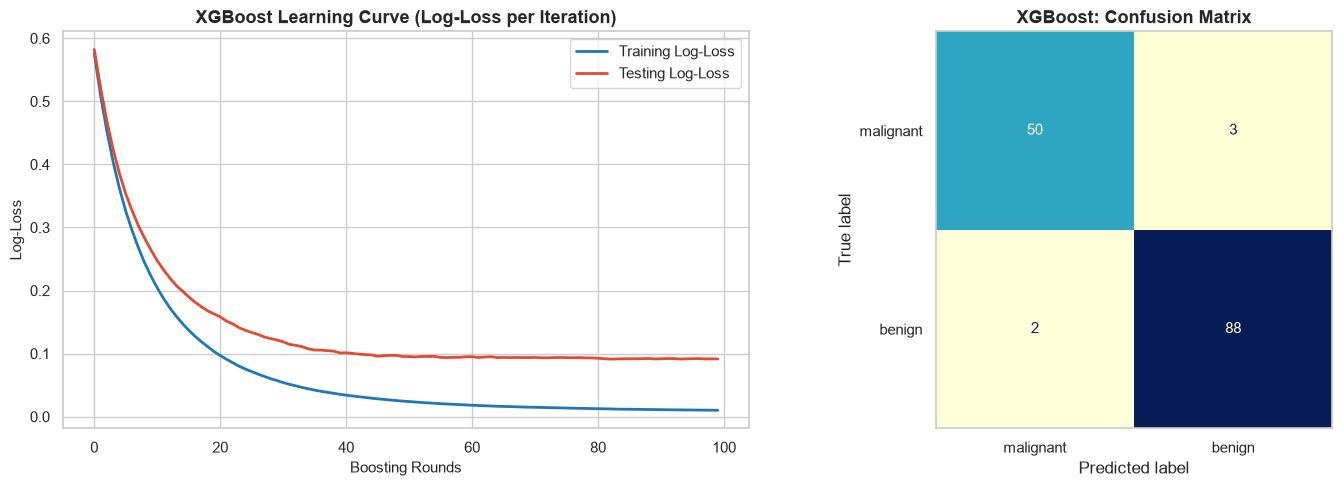

In [56]:
# 8. Visualization: Learning Curve & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Log-Loss Learning Curve
eval_res = xgb_clf.evals_result()
axes[0].plot(eval_res['validation_0']['logloss'], label='Training Log-Loss', color='#1f77b4', linewidth=2)
axes[0].plot(eval_res['validation_1']['logloss'], label='Testing Log-Loss', color='#e24a33', linewidth=2)
axes[0].set_title("XGBoost Learning Curve (Log-Loss per Iteration)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Boosting Rounds", fontsize=11)
axes[0].set_ylabel("Log-Loss", fontsize=11)
axes[0].legend()

# Plot 2: Confusion Matrix
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=cancer_xgb.target_names)
disp_xgb.plot(cmap="YlGnBu", ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("XGBoost: Confusion Matrix", fontsize=13, fontweight="bold")
axes[1].grid(False)

plt.tight_layout()
plt.show()


---
# 8. Comprehensive Ensemble Benchmark & Comparison

Synthesizing all seven ensemble models evaluated on the identical test split to establish an objective leaderboard.


In [57]:
# 8.1 Model Performance Leaderboard Synthesis
from sklearn.metrics import precision_score, recall_score, f1_score

models_dict = {
    "Bagging (Decision Trees)": y_pred_bag,
    "Boosting (AdaBoost)": y_pred_ada,
    "Stacking Ensemble": y_pred_stack,
    "Random Forest": y_pred_rf,
    "Gradient Boosting (GBDT)": y_pred_gb,
    "CatBoost": y_pred_cb,
    "XGBoost": y_pred_xgb
}

benchmark_data = []
for name, preds in models_dict.items():
    benchmark_data.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_bag, preds),
        "Precision": precision_score(y_test_bag, preds),
        "Recall": recall_score(y_test_bag, preds),
        "F1-Score": f1_score(y_test_bag, preds)
    })

df_benchmark = pd.DataFrame(benchmark_data).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

print("=" * 80)
print("ENSEMBLE LEARNING BENCHMARK LEADERBOARD (Breast Cancer Wisconsin)")
print("=" * 80)
display(df_benchmark.round(4))


ENSEMBLE LEARNING BENCHMARK LEADERBOARD (Breast Cancer Wisconsin)


,Model,Accuracy,Precision,Recall,F1-Score
0,Boosting (AdaBoost),0.965,0.9570,0.9889,0.9727
1,CatBoost,0.965,0.9474,1.0000,0.9730
2,XGBoost,0.965,0.9670,0.9778,0.9724
3,Gradient Boosting (GBDT),0.958,0.9468,0.9889,0.9674
4,Random Forest,0.958,0.9565,0.9778,0.9670
5,Stacking Ensemble,0.951,0.9462,0.9778,0.9617
6,Bagging (Decision Trees),0.951,0.9560,0.9667,0.9613


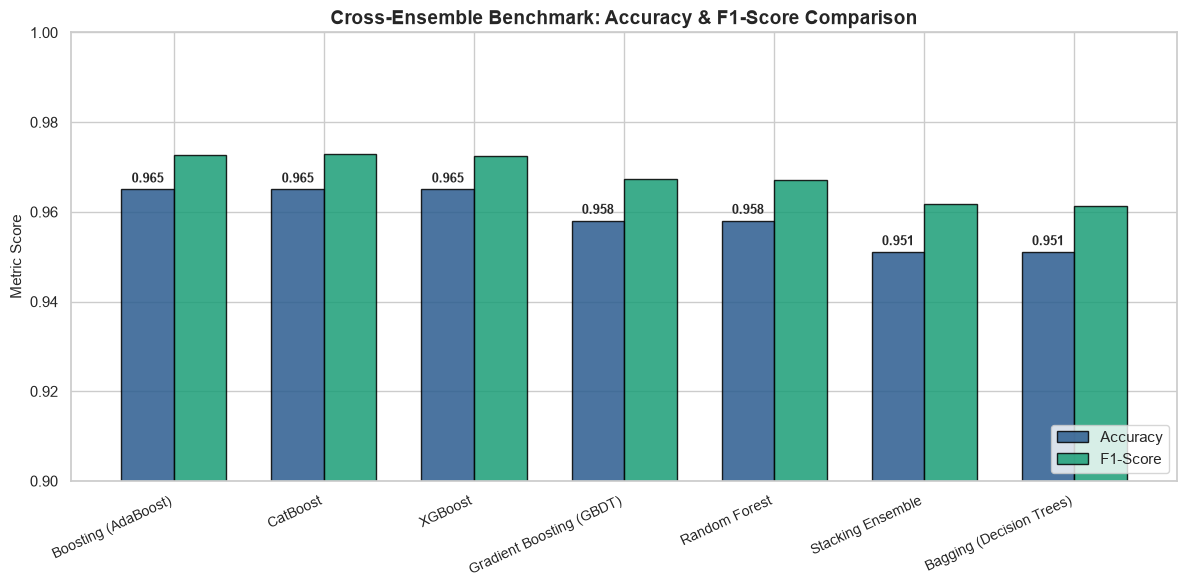

In [58]:
# 8.2 Visualizations: Ensemble Benchmark Comparison Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df_benchmark))
width = 0.35

rects1 = ax.bar(x - width/2, df_benchmark['Accuracy'], width, label='Accuracy', color='#2b5c8f', edgecolor='black', alpha=0.85)
rects2 = ax.bar(x + width/2, df_benchmark['F1-Score'], width, label='F1-Score', color='#1b9e77', edgecolor='black', alpha=0.85)

ax.set_ylabel('Metric Score', fontsize=11)
ax.set_title('Cross-Ensemble Benchmark: Accuracy & F1-Score Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_benchmark['Model'], rotation=25, ha='right', fontsize=10)
ax.set_ylim(0.90, 1.0)
ax.legend(loc='lower right')

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 9. Comparative Summary: Ensemble Learning Architecture Guide

| Ensemble Method | Paradigm | Base Learners | Variance Reduction? | Bias Reduction? | Key Hyperparameters | Best Applied When |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Bagging** | Parallel | Homogeneous (unpruned trees) | **High** | Low | `n_estimators`, `max_samples` | High-variance base models needing stabilization; parallel compute |
| **Boosting (AdaBoost)** | Sequential | Homogeneous (decision stumps) | Low | **High** | `n_estimators`, `learning_rate` | Fast, lightweight bias reduction on clean datasets without extreme noise |
| **Stacking** | Sequential meta-learning | Heterogeneous (RF, KNN, NB, etc.) | Moderate | **High** | `estimators`, `final_estimator`, `cv` | Combining diverse distinct model paradigms for maximum predictive edge |
| **Random Forest** | Parallel | De-correlated decision trees | **Very High** | Low | `n_estimators`, `max_features`, `max_depth` | Default robust baseline; tabular data, high dimensionality |
| **Gradient Boosting (GBDT)**| Sequential | Decision trees on pseudo-residuals | Moderate | **High** | `learning_rate`, `n_estimators`, `subsample` | Complex tabular data with custom loss functions |
| **CatBoost** | Sequential | Oblivious / symmetric trees | Moderate | **High** | `iterations`, `depth`, `learning_rate` | Datasets with categorical features; fast inference requirements |
| **XGBoost** | Sequential | Regularized trees via 2nd-order Taylor | Moderate | **High** | `max_depth`, `learning_rate`, `reg_lambda` | Competitive tabular data; maximum speed and scale with fine-grained regularization |
